# Assignment 3: PAM clustering on the 89 anterior cingulate libraries

This reruns Alice's PAM analysis (`Assignment3_PAM.ipynb`) on the same samples and genes as the k-means and
hierarchical clustering, so the three methods can be compared and shown on one heatmap.

What changed from `Assignment3_PAM.ipynb`, and why:
1. **Samples: 89 AnCg libraries instead of all 266.** With all three regions pooled, PAM k = 2 just separates
   nucleus accumbens (87 + 2 AnCg) from cortex (177), because region is the largest source of variance in this
   dataset. The team analysis uses AnCg only.
2. **Genes filtered to median above 0 in these samples**, same as the other two methods.
3. **Genes z scored before clustering.** On unscaled log2 values the Euclidean PAM objective is nearly flat and
   the answer depends on the implementation: two PAM implementations gave 39 / 50 and 74 / 15 on the same data.
   On z scored genes both give the same answer.
4. **True PAM.** `sklearn_extra`'s `KMedoids` defaults to `method="alternate"`, a faster k-medoids that is not
   PAM, and it has no Windows build for Python 3.12. This uses the `kmedoids` package (`pip install kmedoids`)
   with `method="pam"`.

Kept from Alice's version: Euclidean distance, `random_state=42`, k = 2 to 6, and 10 / 100 / 1,000 / 5,000 /
10,000 genes.

Outputs: `results/a3_labels_pam_ancg.tsv`, `results/a3_pam_k_summary.tsv`, `results/a3_pam_chisq_table.tsv`,
`plots/a3_pam_k_composition.png`

In [1]:
import os
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import kmedoids
from scipy.stats import chi2_contingency
from sklearn.metrics import silhouette_score, adjusted_rand_score
from statsmodels.stats.multitest import multipletests

os.makedirs("plots", exist_ok=True)
os.makedirs("results", exist_ok=True)

DX_ORDER = ["control", "major depression", "bipolar disorder", "schizophrenia"]
DX_NAME = {"control": "Control", "major depression": "Depression",
           "bipolar disorder": "Bipolar", "schizophrenia": "Schizophrenia"}
DX_COLOR = {"control": "#9a9893", "major depression": "#1baf7a",
            "bipolar disorder": "#2a78d6", "schizophrenia": "#eb6834"}
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})

## Step 1: load the processed data (rebuilt from the raw download if the files are missing)

In [2]:
EXPR_LIB, META_LIB = "data/expr_by_library.tsv.gz", "data/meta_by_library.tsv"

if os.path.exists(EXPR_LIB) and os.path.exists(META_LIB):
    expr_lib = pd.read_csv(EXPR_LIB, sep="\t", index_col=0)
    meta_lib = pd.read_csv(META_LIB, sep="\t", index_col=0)
else:
    expr = pd.read_csv("SRP_counts.tsv.gz", sep="\t", index_col="Gene")
    meta = pd.read_csv("metadata.tsv.gz", sep="\t")
    assert list(expr.columns) == meta.refinebio_accession_code.tolist()
    meta[["region", "dx"]] = meta.refinebio_subject.str.split("_", n=1, expand=True)
    meta["donor"] = meta.refinebio_title.str.split("_").str[0]
    run_to_lib = meta.set_index("refinebio_accession_code").refinebio_title
    expr_lib = expr.T.groupby(run_to_lib).mean().T
    meta_lib = (meta.drop_duplicates("refinebio_title").set_index("refinebio_title")
                    .loc[expr_lib.columns])
    os.makedirs("data", exist_ok=True)
    expr_lib.to_csv(EXPR_LIB, sep="\t")
    meta_lib.to_csv(META_LIB, sep="\t")

sl = meta_lib.index.str.extract(r"SL(\d+)")[0].astype(int).values
meta_lib["batch"] = np.where(sl > 20000, "B", "A")

meta_a = meta_lib[meta_lib.region == "ancg"].copy()
log_expr = np.log2(expr_lib[meta_a.index] + 1)
log_expr = log_expr[log_expr.median(axis=1) > 0]
print("genes x libraries:", log_expr.shape)

gene_rank = log_expr.var(axis=1).sort_values(ascending=False).index

def top_z(n):
    X = log_expr.loc[gene_rank[:n]].T
    return (X - X.mean()) / X.std()

def pam(X, k):
    # labels returned as 1..k
    return kmedoids.KMedoids(n_clusters=k, method="pam", metric="euclidean",
                             random_state=42).fit_predict(X.values) + 1

genes x libraries: (34916, 89)


## Step 2b to 2d: PAM on 5,000 genes, k = 2 to 6
PAM needs k up front. Unlike hierarchical clustering the solutions are not nested, so each k is a separate run
and libraries can move between clusters as k changes.

In [3]:
Z5000 = top_z(5000)
KS = [2, 3, 4, 5, 6]
labels = pd.DataFrame(index=meta_a.index)
labels.index.name = "refinebio_title"
summary = []
for k in KS:
    lab = pam(Z5000, k)
    labels[f"g5000_k{k}"] = lab
    summary.append({"k": k, "cluster_sizes": " / ".join(map(str, np.bincount(lab)[1:])),
                    "silhouette": silhouette_score(Z5000, lab),
                    "batch_chi2_p": chi2_contingency(pd.crosstab(lab, meta_a.batch))[1]})
    tab = pd.crosstab(lab, meta_a.dx).reindex(columns=DX_ORDER, fill_value=0)
    tab["batch B"] = pd.crosstab(lab, meta_a.batch).get("B", 0)
    print(f"\n=== k = {k} ===")
    print(tab.rename(columns=DX_NAME).to_string())

summary = pd.DataFrame(summary)
summary.to_csv("results/a3_pam_k_summary.tsv", sep="\t", index=False)
summary.round(3)


=== k = 2 ===
dx     Control  Depression  Bipolar  Schizophrenia  batch B
row_0                                                      
1           22          22       14             16       15
2            0           0        8              7        2

=== k = 3 ===
dx     Control  Depression  Bipolar  Schizophrenia  batch B
row_0                                                      
1           15          17       11             11       15
2            7           5        3              5        0
3            0           0        8              7        2



=== k = 4 ===
dx     Control  Depression  Bipolar  Schizophrenia  batch B
row_0                                                      
1            9          13        6              6        1
2            7           5        3              5        0
3            0           0        7              5        0
4            6           4        6              7       16

=== k = 5 ===
dx     Control  Depression  Bipolar  Schizophrenia  batch B
row_0                                                      
1            7           5        3              5        0
2            9          13        6              6        1
3            0           0        5              4        0
4            6           4        6              7       16
5            0           0        2              1        0

=== k = 6 ===
dx     Control  Depression  Bipolar  Schizophrenia  batch B
row_0                                                      
1            8           6        2              4     

,k,cluster_sizes,silhouette,batch_chi2_p
0,2,74 / 15,0.306,0.793
1,3,54 / 20 / 15,0.112,0.022
2,4,34 / 20 / 12 / 23,0.067,0.000
3,5,20 / 34 / 9 / 23 / 3,0.063,0.000
4,6,20 / 9 / 23 / 3 / 12 / 22,0.057,0.000


In [4]:
# how memberships move between consecutive k (rows = smaller k, columns = larger k)
for a, b in zip(KS[:-1], KS[1:]):
    print(f"\nk = {a} (rows) vs k = {b} (columns)")
    print(pd.crosstab(labels[f"g5000_k{a}"], labels[f"g5000_k{b}"]).to_string())


k = 2 (rows) vs k = 3 (columns)
g5000_k3   1   2   3
g5000_k2            
1         54  20   0
2          0   0  15

k = 3 (rows) vs k = 4 (columns)


g5000_k4   1   2   3   4
g5000_k3                
1         34   0   0  20
2          0  20   0   0
3          0   0  12   3

k = 4 (rows) vs k = 5 (columns)
g5000_k5   1   2  3   4  5
g5000_k4                  
1          0  34  0   0  0
2         20   0  0   0  0
3          0   0  9   0  3
4          0   0  0  23  0

k = 5 (rows) vs k = 6 (columns)
g5000_k6   1  2   3  4  5   6
g5000_k5                     
1         15  0   0  0  5   0
2          5  0  23  0  6   0
3          0  9   0  0  0   0
4          0  0   0  0  1  22
5          0  0   0  3  0   0


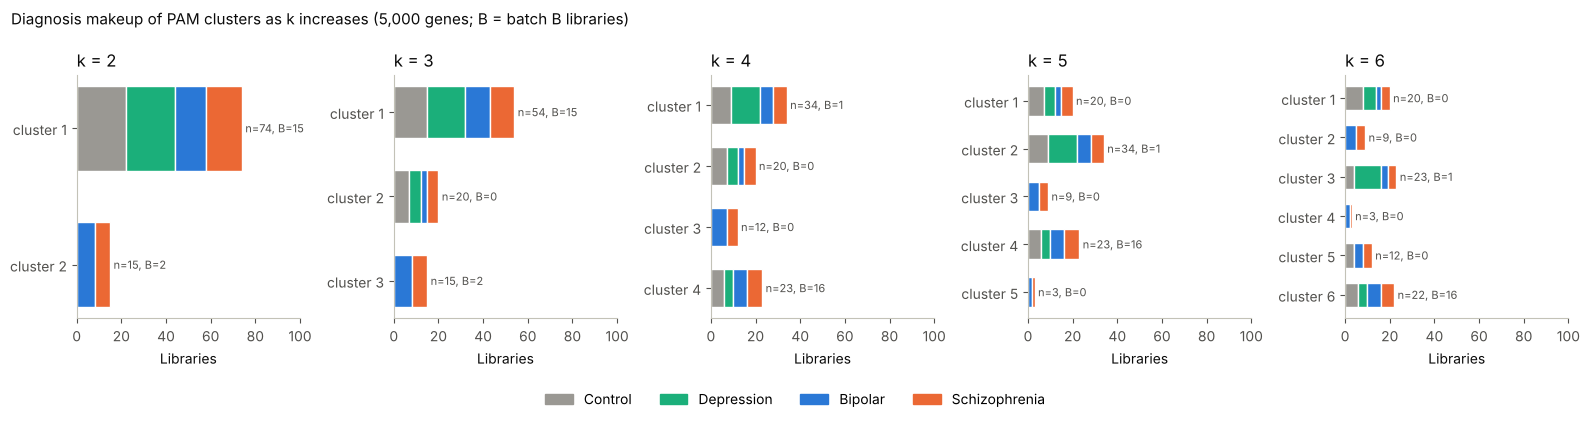

In [5]:
# Figure: diagnosis makeup of each PAM cluster at each k
fig, axes = plt.subplots(1, len(KS), figsize=(16, 3.8), sharex=True)
for ax, k in zip(axes, KS):
    tab = pd.crosstab(labels[f"g5000_k{k}"], meta_a.dx).reindex(columns=DX_ORDER, fill_value=0)
    nb = pd.crosstab(labels[f"g5000_k{k}"], meta_a.batch).get("B", pd.Series(0, index=tab.index))
    left = np.zeros(len(tab))
    y = np.arange(len(tab))[::-1]
    for d in DX_ORDER:
        ax.barh(y, tab[d], left=left, color=DX_COLOR[d], height=0.62, edgecolor="white", linewidth=1)
        left += tab[d].values
    for yi, tot, b in zip(y, left, nb.values):
        ax.text(tot + 1.5, yi, f"n={int(tot)}, B={int(b)}", va="center", fontsize=8, color=MUTED)
    ax.set_yticks(y); ax.set_yticklabels([f"cluster {c}" for c in tab.index])
    ax.set_title(f"k = {k}", loc="left", color=INK)
    ax.set_xlim(0, 100); ax.set_xlabel("Libraries")
fig.legend(handles=[Patch(color=DX_COLOR[d], label=DX_NAME[d]) for d in DX_ORDER],
           loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Diagnosis makeup of PAM clusters as k increases (5,000 genes; B = batch B libraries)",
             x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout()
fig.savefig("plots/a3_pam_k_composition.png")
plt.show()

## Step 2e: 10, 100, 1,000 and 10,000 genes (k = 2)

In [6]:
GENE_COUNTS = [10, 100, 1000, 5000, 10000]
for n in GENE_COUNTS:
    if n != 5000:
        labels[f"g{n}_k2"] = pam(top_z(n), 2)
gene_cols = [f"g{n}_k2" for n in GENE_COUNTS]
for c in gene_cols:
    tab = pd.crosstab(labels[c], meta_a.dx).reindex(columns=DX_ORDER, fill_value=0)
    print(f"\n{c}  ARI vs 5,000 genes = {adjusted_rand_score(labels['g5000_k2'], labels[c]):.2f}")
    print(tab.rename(columns=DX_NAME).to_string())

pd.DataFrame([[adjusted_rand_score(labels[a], labels[b]) for b in gene_cols] for a in gene_cols],
             index=GENE_COUNTS, columns=GENE_COUNTS).round(2)


g10_k2  ARI vs 5,000 genes = 0.23
dx      Control  Depression  Bipolar  Schizophrenia
g10_k2                                             
1             3           7       11             12
2            19          15       11             11

g100_k2  ARI vs 5,000 genes = 0.22
dx       Control  Depression  Bipolar  Schizophrenia
g100_k2                                             
1             15          18        9             11
2              7           4       13             12

g1000_k2  ARI vs 5,000 genes = -0.00
dx        Control  Depression  Bipolar  Schizophrenia
g1000_k2                                             
1              10          13        6              7
2              12           9       16             16

g5000_k2  ARI vs 5,000 genes = 1.00
dx        Control  Depression  Bipolar  Schizophrenia
g5000_k2                                             
1              22          22       14             16
2               0           0        8              7

g

,10,100,1000,5000,10000
10,1.00,0.27,0.13,0.23,0.23
100,0.27,1.00,0.11,0.22,0.22
1000,0.13,0.11,1.00,-0.00,-0.00
5000,0.23,0.22,-0.00,1.00,1.00
10000,0.23,0.22,-0.00,1.00,1.00


## Steps 2e.ii and 4: chi square tests with BH adjustment
Gene count pairs at k = 2 (10), k pairs at 5,000 genes (10), and every version against diagnosis (9),
all adjusted together. Unlike hierarchical clustering, PAM's k vs k tests are not guaranteed to be significant
because the runs are independent, but they are still expected to be, since each run finds similar structure.

In [7]:
def chi_row(name, kind, a, b):
    ct = pd.crosstab(a, b)
    chi2, p, dof, exp = chi2_contingency(ct)
    return {"comparison": name, "type": kind, "chi2": chi2, "df": dof, "p_value": p,
            "ARI": adjusted_rand_score(a, b), "min_expected": exp.min(),
            "pct_expected_below_5": 100 * (exp < 5).mean()}

rows = []
for a, b in combinations(GENE_COUNTS, 2):
    rows.append(chi_row(f"{a:,} vs {b:,} genes (k=2)", "gene count vs gene count",
                        labels[f"g{a}_k2"], labels[f"g{b}_k2"]))
for a, b in combinations(KS, 2):
    rows.append(chi_row(f"k={a} vs k={b} (5,000 genes)", "k vs k",
                        labels[f"g5000_k{a}"], labels[f"g5000_k{b}"]))
versions = gene_cols + [f"g5000_k{k}" for k in KS[1:]]
for v in versions:
    n, k = v[1:].split("_k")
    rows.append(chi_row(f"{int(n):,} genes, k={k} vs diagnosis", "clusters vs diagnosis",
                        labels[v], meta_a.dx))

chisq = pd.DataFrame(rows)
chisq.insert(5, "p_adj_BH", multipletests(chisq.p_value, method="fdr_bh")[1])
chisq["method"] = "PAM"
chisq.to_csv("results/a3_pam_chisq_table.tsv", sep="\t", index=False)
with pd.option_context("display.width", 200):
    print(chisq.drop(columns=["method"]).to_string(
        formatters={"chi2": "{:.2f}".format, "p_value": "{:.2e}".format, "p_adj_BH": "{:.2e}".format,
                    "ARI": "{:.2f}".format, "min_expected": "{:.2f}".format,
                    "pct_expected_below_5": "{:.0f}".format}))

                        comparison                      type   chi2  df  p_value p_adj_BH   ARI min_expected pct_expected_below_5
0            10 vs 100 genes (k=2)  gene count vs gene count  20.60   1 5.65e-06 1.36e-05  0.27        13.35                    0
1          10 vs 1,000 genes (k=2)  gene count vs gene count  15.65   1 7.61e-05 1.30e-04  0.13        13.35                    0
2          10 vs 5,000 genes (k=2)  gene count vs gene count  16.54   1 4.75e-05 8.62e-05  0.23         5.56                    0
3         10 vs 10,000 genes (k=2)  gene count vs gene count  16.54   1 4.75e-05 8.62e-05  0.23         5.56                    0
4         100 vs 1,000 genes (k=2)  gene count vs gene count  12.59   1 3.89e-04 6.26e-04  0.11        14.56                    0
5         100 vs 5,000 genes (k=2)  gene count vs gene count  18.39   1 1.80e-05 3.73e-05  0.22         6.07                    0
6        100 vs 10,000 genes (k=2)  gene count vs gene count  18.39   1 1.80e-05 3.73e-05 

## Save labels for the combined heatmap, and compare with hierarchical clustering

In [8]:
labels.to_csv("results/a3_labels_pam_ancg.tsv", sep="\t")
if os.path.exists("results/a3_labels_hclust.tsv"):
    hc = pd.read_csv("results/a3_labels_hclust.tsv", sep="\t", index_col=0).loc[labels.index]
    print("ARI, PAM vs hierarchical, 5,000 genes k=2:",
          round(adjusted_rand_score(labels["g5000_k2"], hc["g5000_k2"]), 2))
    print(pd.crosstab(labels["g5000_k2"].rename("PAM"), hc["g5000_k2"].rename("hierarchical")))

ARI, PAM vs hierarchical, 5,000 genes k=2: 1.0
hierarchical   1   2
PAM                 
1              0  74
2             15   0
